# 06 - Booking Behavior Analysis 🧠

**Questions to answer:**
- How far in advance do people typically book (lead time)?
- Do early bookings cancel more than late bookings?
- What's the average stay duration, and how does it differ between City and Resort hotels?

In [1]:
import sys
sys.path.append('..')

import pandas as pd

from src.config import CLEAN_DATA_PATH
from src.feature_engineering import add_stay_features
from src.analysis import stay_duration_by_hotel, lead_time_by_cancellation
from src.visualization import plot_lead_time_by_cancellation, plot_stay_duration_by_hotel

df = pd.read_csv(CLEAN_DATA_PATH)
df = add_stay_features(df)

## Lead time distribution (revisited with cancellation split)

is_canceled
0    38.0
1    80.0
Name: lead_time, dtype: float64

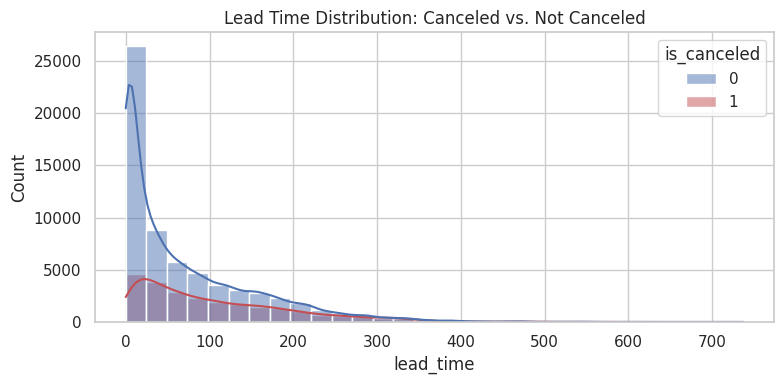

In [2]:
plot_lead_time_by_cancellation(lead_time_by_cancellation(df))
df.groupby('is_canceled')['lead_time'].median()

## Stay duration: City vs Resort

hotel
City Hotel      3.142111
Resort Hotel    4.391463
Name: total_stay, dtype: float64

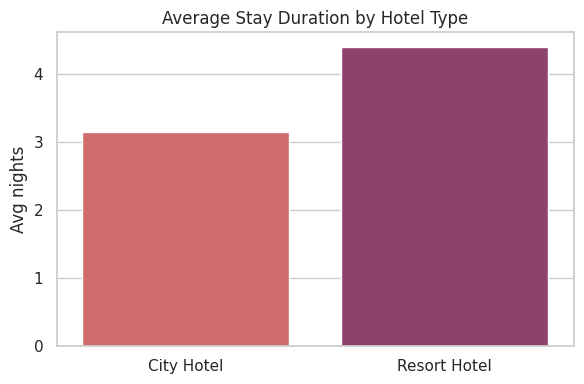

In [3]:
stay_by_hotel = stay_duration_by_hotel(df)
plot_stay_duration_by_hotel(stay_by_hotel)
stay_by_hotel

## Key insight

In [4]:
median_canceled = df.loc[df['is_canceled'] == 1, 'lead_time'].median()
median_not = df.loc[df['is_canceled'] == 0, 'lead_time'].median()
longer_hotel = stay_by_hotel.idxmax()
print(f"- Canceled bookings have a median lead time of {median_canceled:.0f} days vs {median_not:.0f} days for completed stays — booking far ahead is a real risk signal.")
print(f"- {longer_hotel} guests stay longer on average ({stay_by_hotel.max():.1f} nights vs {stay_by_hotel.min():.1f}).")

- Canceled bookings have a median lead time of 80 days vs 38 days for completed stays — booking far ahead is a real risk signal.
- Resort Hotel guests stay longer on average (4.4 nights vs 3.1).
